# Exp3

C:\Users\ARJUN\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


(128, 64, 32) relu Loss: 1.57 Accuracy: 0.439
(128, 64, 32) tanh Loss: 1.75 Accuracy: 0.381
(128, 64, 32) sigmoid Loss: 1.723 Accuracy: 0.376
(256, 128, 64) relu Loss: 1.554 Accuracy: 0.444
(256, 128, 64) tanh Loss: 1.739 Accuracy: 0.37
(256, 128, 64) sigmoid Loss: 1.647 Accuracy: 0.401
(1024, 512, 256) relu Loss: 1.448 Accuracy: 0.484
(1024, 512, 256) tanh Loss: 1.912 Accuracy: 0.292
(1024, 512, 256) sigmoid Loss: 1.588 Accuracy: 0.428
Predicted: Deer | Actual: Deer


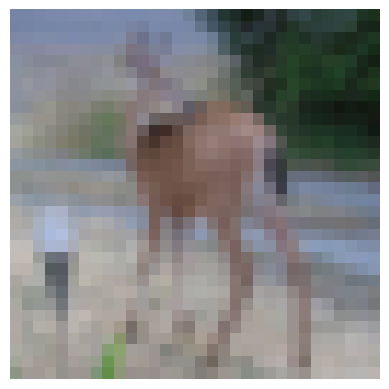

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Flatten, Dense
from tensorflow.keras.utils import to_categorical



(x, y), (xt, yt) = cifar10.load_data()
"""
train_ds = tf.keras.utils.image_dataset_from_directory(
"cifar10",
batch_size=32
)
"""
x, xt = x / 255.0, xt / 255.0
y, yt = to_categorical(y), to_categorical(yt)

classes = ['Airplane', 'Automobile', 'Bird', 'Cat', 'Deer',
           'Dog', 'Frog', 'Horse', 'Ship', 'Truck']

best, best_acc = None, 0

for units in [(128, 64, 32), (256, 128, 64), (1024, 512, 256)]:
    for act in ['relu', 'tanh', 'sigmoid']:
        m = Sequential([Flatten(input_shape=(32, 32, 3)),
                        Dense(units[0], activation=act),
                        Dense(units[1], activation=act),
                        Dense(units[2], activation=act),
                        Dense(10, activation='softmax')])
        m.compile(optimizer='adam', loss='categorical_crossentropy',
                  metrics=['accuracy'])
        m.fit(x, y, epochs=5, batch_size=64, verbose=0)
        loss, acc = m.evaluate(xt, yt, verbose=0)
        print(units, act, "Loss:", round(loss, 3), "Accuracy:", round(acc, 3))
        if acc > best_acc:
            best, best_acc = m, acc

i = 100
p = best.predict(xt[i:i+1], verbose=0).argmax()
print("Predicted:", classes[p], "| Actual:", classes[yt[i].argmax()])
plt.imshow(xt[i])
plt.axis('off')
plt.show()

# Exp 4


In [ ]:

import tensorflow as tf
import pandas as pd
import time
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.regularizers import l1,l2
from tensorflow.keras.utils import to_categorical

(x,y),(xt,yt)=cifar10.load_data()
x,xt=x/255.0,xt/255.0
y,yt=to_categorical(y),to_categorical(yt)

configs=[("Baseline","glorot_uniform",None,0),
("Xavier","glorot_uniform",None,0),("Dropout","glorot_uniform",None,1),
("L1","glorot_uniform",l1(.001),0),("L2","glorot_uniform",l2(.001),0),
("He Normal","he_normal",None,0)]
results=[]

for name,init,reg,drop in configs:
 for opt,lr in [("Adam",.001),("SGD",.01)]:
  m=Sequential([Input((32,32,3)),Flatten()])
  for units in [512,256,64]:
   m.add(Dense(units,activation='relu',kernel_initializer=init,kernel_regularizer=reg))
   if drop: m.add(Dropout(.5))
  m.add(Dense(10,activation='softmax'))
  m.compile(tf.keras.optimizers.Adam(lr) if opt=="Adam" else tf.keras.optimizers.SGD(lr),
            'categorical_crossentropy',metrics=['accuracy'])
  t=time.time()
  m.fit(x,y,epochs=5,batch_size=64,validation_data=(xt,yt),verbose=0)
  loss,acc=m.evaluate(xt,yt,verbose=0)
  results.append([name,opt,round(loss,4),round(acc*100,2),round(time.time()-t,2)])

df=pd.DataFrame(results,columns=["Model","Optimizer","Loss","Accuracy (%)","Time (s)"])
print(df.to_string(index=False))
print("\nTraining Time Comparison")
print(df[["Model","Optimizer","Time (s)"]].to_string(index=False))


    Model Optimizer   Loss  Accuracy (%)  Time (s)
 Baseline      Adam 1.5201         45.51     39.75
 Baseline       SGD 1.6281         42.76     17.06
   Xavier      Adam 1.4991         46.22     41.99
   Xavier       SGD 1.7742         37.30     16.15
  Dropout      Adam 2.0938         19.65     49.15
  Dropout       SGD 1.8364         36.04     18.63
       L1      Adam 2.2157         30.18     45.78
       L1       SGD 5.5198         17.17     35.81
       L2      Adam 1.7718         40.51     52.40
       L2       SGD 2.8406         38.55     38.89
He Normal      Adam 1.5457         44.87     41.81
He Normal       SGD 1.7848         38.52     23.15
  Kaiming      Adam 1.5098         46.11     42.69
  Kaiming       SGD 1.6561         41.14     15.72

Training Time Comparison
    Model Optimizer  Time (s)
 Baseline      Adam     39.75
 Baseline       SGD     17.06
   Xavier      Adam     41.99
   Xavier       SGD     16.15
  Dropout      Adam     49.15
  Dropout       SGD     18.63

# Exp 5


C:\Users\ARJUN\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



========== MODEL 1 RESULTS ==========
Accuracy: 98.41 %
Loss: 0.0491


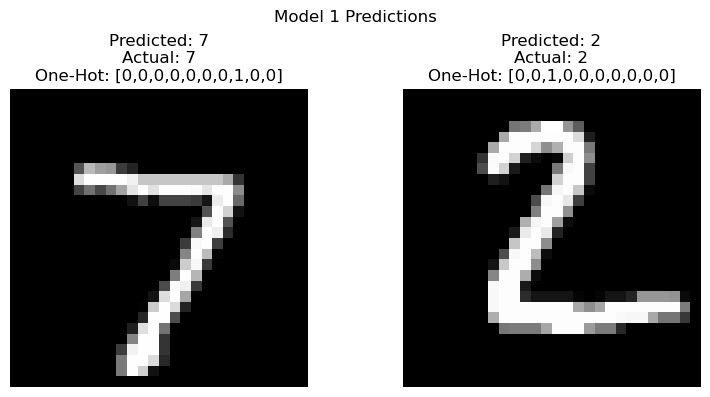


========== MODEL 2 RESULTS ==========
Accuracy: 98.81 %
Loss: 0.0397


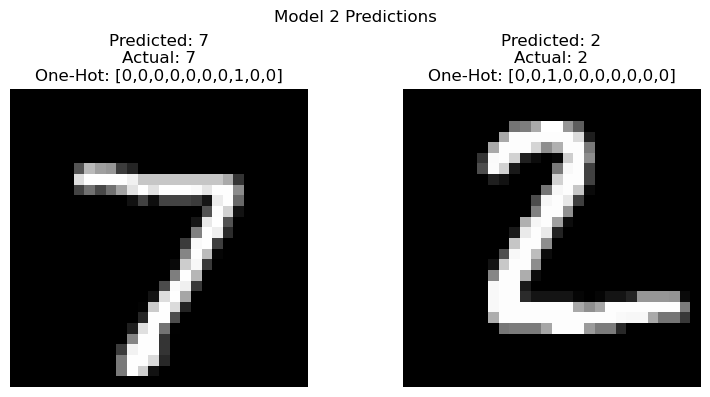

In [1]:

import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense
from tensorflow.keras.utils import to_categorical

(x_train, y_train), (x_test, y_test) = mnist.load_data()

x_train = x_train.reshape(60000, 28, 28, 1) / 255.0
x_test = x_test.reshape(10000, 28, 28, 1) / 255.0
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)

# Model 1: one Conv block
model1 = Sequential()
model1.add(Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)))
model1.add(MaxPooling2D((2, 2)))
model1.add(Flatten())
model1.add(Dense(128, activation="relu"))
model1.add(Dense(10, activation="softmax"))

# Model 2: two Conv blocks
model2 = Sequential()
model2.add(Conv2D(32, (3, 3), activation="relu", input_shape=(28, 28, 1)))
model2.add(MaxPooling2D((2, 2)))
model2.add(Conv2D(64, (3, 3), activation="relu"))
model2.add(MaxPooling2D((2, 2)))
model2.add(Flatten())
model2.add(Dense(128, activation="relu"))
model2.add(Dense(10, activation="softmax"))

# ---------- Model 1 ----------
model1.compile(optimizer="adam", loss="categorical_crossentropy",
                metrics=["accuracy"])
model1.fit(x_train, y_train, epochs=5, batch_size=64)
loss1, acc1 = model1.evaluate(x_test, y_test)
pred1 = model1.predict(x_test[:2])

print("\n========== MODEL 1 RESULTS ==========")
print("Accuracy:", round(acc1 * 100, 2), "%")
print("Loss:", round(loss1, 4))

plt.figure(figsize=(8, 4))

# first test image
plt.subplot(1, 2, 1)
plt.imshow(x_test[0].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {pred1[0].argmax()}\nActual: {y_test[0].argmax()}")
plt.axis("off")

# second test image
plt.subplot(1, 2, 2)
plt.imshow(x_test[1].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {pred1[1].argmax()}\nActual: {y_test[1].argmax()}")
plt.axis("off")

plt.suptitle("Model 1 Predictions")
plt.tight_layout()
plt.show()

# ---------- Model 2 ----------
model2.compile(optimizer="adam", loss="categorical_crossentropy",
                metrics=["accuracy"])
model2.fit(x_train, y_train, epochs=5, batch_size=64)
loss2, acc2 = model2.evaluate(x_test, y_test)
pred2 = model2.predict(x_test[:2])

print("\n========== MODEL 2 RESULTS ==========")
print("Accuracy:", round(acc2 * 100, 2), "%")
print("Loss:", round(loss2, 4))

plt.figure(figsize=(8, 4))

# first test image
plt.subplot(1, 2, 1)
plt.imshow(x_test[0].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {pred2[0].argmax()}\nActual: {y_test[0].argmax()}")
plt.axis("off")

# second test image
plt.subplot(1, 2, 2)
plt.imshow(x_test[1].reshape(28, 28), cmap="gray")
plt.title(f"Predicted: {pred2[1].argmax()}\nActual: {y_test[1].argmax()}")
plt.axis("off")

plt.suptitle("Model 2 Predictions")
plt.tight_layout()
plt.show()


# exp 6

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import mnist
from tensorflow.keras.applications import VGG19
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout

(x_train, y_train), (x_test, y_test) = mnist.load_data()

# keep only part of the data (VGG19 is slow)
x_train = x_train[:5000]
y_train = y_train[:5000]
x_test = x_test[:1000]
y_test = y_test[:1000]

# prepare training images for VGG19
x_train = x_train.reshape(5000, 28, 28, 1)        # add channel
x_train = tf.cast(x_train, tf.float32)            # whole numbers -> decimals
x_train = tf.image.grayscale_to_rgb(x_train)      # 1 channel -> 3 channels
x_train = tf.image.resize(x_train, (64, 64))      # 28x28 -> 64x64
x_train = preprocess_input(x_train)               # VGG19's own formatting

# prepare test images the same way
x_test = x_test.reshape(1000, 28, 28, 1)
x_test = tf.cast(x_test, tf.float32)
x_test = tf.image.grayscale_to_rgb(x_test)
x_test = tf.image.resize(x_test, (64, 64))
x_test = preprocess_input(x_test)

# pretrained VGG19 without its top (classifier) part
vgg = VGG19(weights="imagenet", include_top=False, input_shape=(64, 64, 3))

model = Sequential([
    vgg,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

# ---------- Stage 1: VGG19 frozen, only new layers learn ----------
vgg.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history1 = model.fit(x_train, y_train, epochs=1, batch_size=128, validation_split=0.2)

plt.plot(history1.history["accuracy"])
plt.plot(history1.history["val_accuracy"])
plt.title("Stage 1 - accuracy")
plt.legend(["Training", "Validation"])
plt.show()

plt.plot(history1.history["loss"])
plt.plot(history1.history["val_loss"])
plt.title("Stage 1 - loss")
plt.legend(["Training", "Validation"])
plt.show()

# ---------- Stage 2: fine-tune the last 8 layers of VGG19 ----------
vgg.trainable = True
for layer in vgg.layers[:14]:     # VGG19 has 22 layers: freeze first 14, train last 8
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.00001),
              loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])
history2 = model.fit(x_train, y_train, epochs=1, batch_size=128, validation_split=0.2)

plt.plot(history2.history["accuracy"])
plt.plot(history2.history["val_accuracy"])
plt.title("Stage 2 - accuracy")
plt.legend(["Training", "Validation"])
plt.show()

plt.plot(history2.history["loss"])
plt.plot(history2.history["val_loss"])
plt.title("Stage 2 - loss")
plt.legend(["Training", "Validation"])
plt.show()


80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
Epoch 1/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 35s 278ms/step - accuracy: 0.5845 - loss: 2.6119 - val_accuracy: 0.8410 - val_loss: 0.5072
Epoch 2/3
125/125 ━━━━━━━━━━━━━━━━━━━━ 38s 306ms/step - accuracy: 0.8217 - loss: 0.5516 - val_accuracy: 0.8830 - val_loss: 0.3799
Epoch 3/3
 31/125 ━━━━━━━━━━━━━━━━━━━━ 23s 250ms/step - accuracy: 0.8639 - loss: 0.4086

# exp 7

[*********************100%***********************]  1 of 1 completed

Epoch 1/50



C:\Users\ARJUN\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 0.0207 
Epoch 2/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0190 
Epoch 3/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0113 
Epoch 4/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0080 
Epoch 5/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0070 
Epoch 6/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0055 
Epoch 7/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0056 
Epoch 8/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0051 
Epoch 9/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0046 
Epoch 10/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0041 
Epoch 11/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0035     
Epoch 12/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0035 
Epoch 13/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0034     
Epoch 14/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0031 
Epoch 15/50
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0029     
Epo

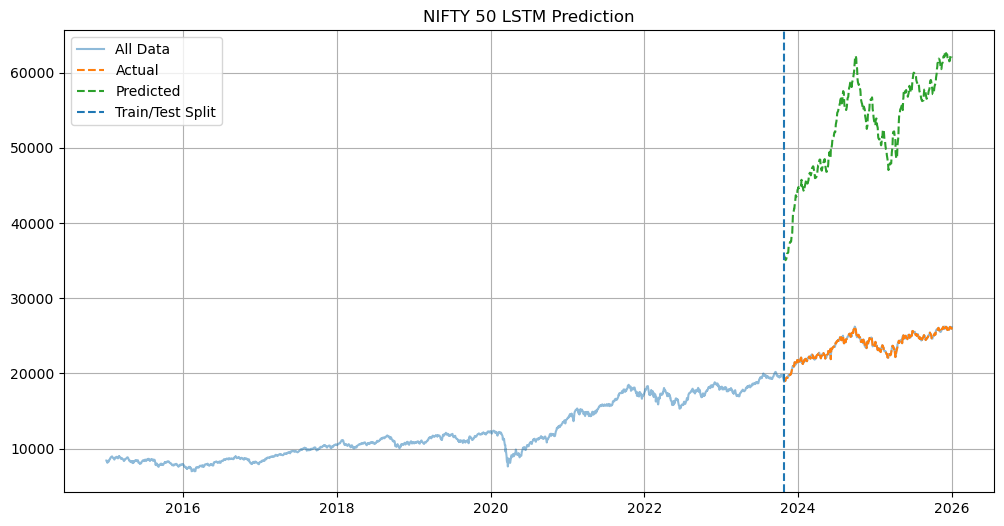

In [3]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

df = yf.download("^NSEI", start="2015-01-01", end="2026-01-01", multi_level_index=False)
df = df[["Open", "High", "Low", "Close"]].dropna()

scaler = MinMaxScaler()
data = scaler.fit_transform(df)          # all prices scaled to 0-1

X = []
y = []
for i in range(len(data) - 20):
    X.append(data[i:i+20])               # 20 days of Open, High, Low, Close
    y.append(data[i+20, 3])              # the next day's Close
X = np.array(X)
y = np.array(y)

split = int(len(X) * 0.8)                # first 80% train, last 20% test
X_train, y_train = X[:split], y[:split]
X_test, y_test = X[split:], y[split:]

model = Sequential([
    LSTM(64, input_shape=(20, 4)),
    Dropout(0.2),
    BatchNormalization(),
    Dense(32, activation="relu"),
    Dense(1)
])
model.compile(optimizer="adam", loss="mse")
model.fit(X_train, y_train, epochs=50, batch_size=32, shuffle=False,
          callbacks=[EarlyStopping(monitor="loss", patience=5, restore_best_weights=True)])

pred = model.predict(X_test)

# undo the 0-1 scaling: price = scaled * (max - min) + min
low = df["Close"].min()
high = df["Close"].max()
actual = y_test * (high - low) + low
predicted = pred * (high - low) + low

print("MAE:", mean_absolute_error(actual, predicted))
print("MSE:", mean_squared_error(actual, predicted))

plt.figure(figsize=(12, 6))
plt.plot(actual, label="Actual")
plt.plot(predicted, label="Predicted")
plt.title("NIFTY 50 LSTM Prediction")
plt.legend()
plt.show()


# Exp 8

In [4]:

from tensorflow.keras.datasets import imdb
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.preprocessing.sequence import pad_sequences

(x,y),(xt,yt)=imdb.load_data(num_words=10000)
x=pad_sequences(x,maxlen=200)
xt=pad_sequences(xt,maxlen=200)

m=Sequential([Embedding(10000,32),SimpleRNN(32),Dense(1,activation='sigmoid')])
m.compile('adam','binary_crossentropy',metrics=['accuracy'])
m.fit(x,y,epochs=5,batch_size=64)

loss,acc=m.evaluate(xt,yt)
print("Test Loss:",loss,"\nTest Accuracy:",acc)

p=m.predict(xt[:1],verbose=0)[0][0]
print("Prediction:",p)
print("Review:","Positive" if p>=.5 else "Negative")


Epoch 1/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.6348 - loss: 0.6213
Epoch 2/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 11ms/step - accuracy: 0.8172 - loss: 0.4072
Epoch 3/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9146 - loss: 0.2204
Epoch 4/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9720 - loss: 0.0901
Epoch 5/5
391/391 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.9901 - loss: 0.0372
782/782 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.7567 - loss: 0.7458
Test Loss: 0.7457588315010071 
Test Accuracy: 0.7567200064659119
Prediction: 0.03239351
Review: Negative


# EXP 2


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("jommuFLOWER.jpg")                         # OpenCV loads colours as BGR
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)             # BGR -> RGB so matplotlib shows true colours
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)               # colour -> grayscale

kernel = np.ones((5, 5), np.uint8)                         # 5x5 square of 1s
opening = cv2.morphologyEx(gray, cv2.MORPH_OPEN, kernel)   # removes small bright spots
closing = cv2.morphologyEx(gray, cv2.MORPH_CLOSE, kernel)  # fills small dark holes

plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(img_rgb)
plt.title("Original")

plt.subplot(2, 2, 2)
plt.imshow(gray, cmap="gray")
plt.title("Grayscale")

plt.subplot(2, 2, 3)
plt.imshow(opening, cmap="gray")
plt.title("Opening")

plt.subplot(2, 2, 4)
plt.imshow(closing, cmap="gray")
plt.title("Closing")

plt.show()
